In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
df = pd.read_csv("churn.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [3]:
df = df.drop(["RowNumber", "CustomerId", "Surname"], axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


In [4]:
unique_exited_rows = df["Exited"].unique().tolist()
print(unique_exited_rows)
unique_gender_rows = df["Gender"].unique().tolist()
print(unique_gender_rows)
unique_geography_rows = df["Geography"].unique().tolist()
print(unique_geography_rows)
unique_numOfProducts_rows = df["NumOfProducts"].unique().tolist()
print(unique_numOfProducts_rows)

[1, 0]
['Female', 'Male']
['France', 'Spain', 'Germany']
[1, 3, 2, 4]


In [5]:
import seaborn as sns

sns.set_theme(style="whitegrid", palette="pastel")
# plot1 = sns.countplot(df, x="Exited")
# plot1.set_title("Count of Exited")
# churn_rate = (df["Exited"].sum() / len(df)) * 100
# print(churn_rate)

Text(0.5, 1.0, 'Age vs Exited (Age Factor)')

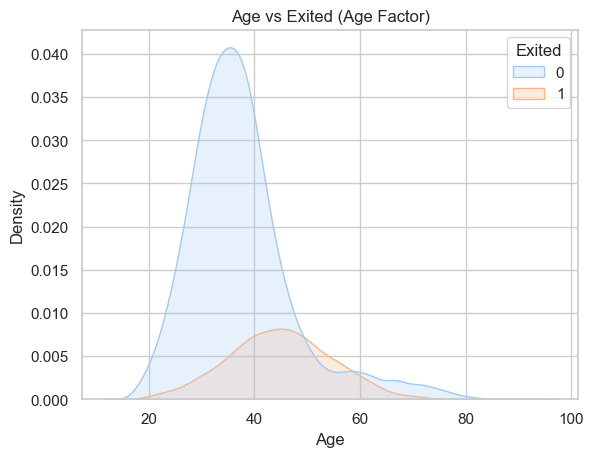

In [6]:
plot2 = sns.kdeplot(data=df, x='Age', hue='Exited', fill=True)
plot2.set_title("Age vs Exited (Age Factor)")
# fig = plot2.get_figure()
# fig.savefig("./images/age_vs_exited.png", dpi=300, bbox_inches='tight')

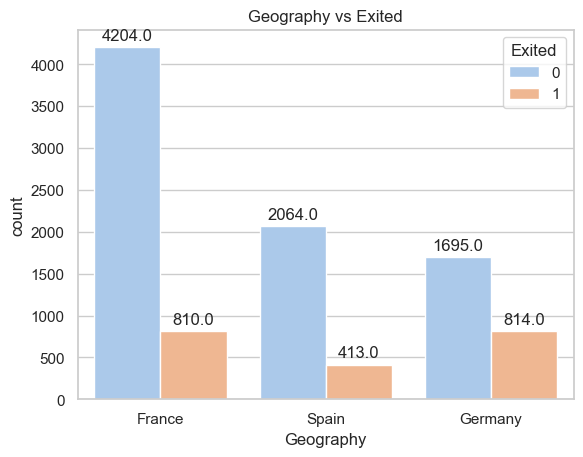

In [7]:
plot3 = sns.countplot(data=df, x='Geography', hue='Exited')
plot3.set_title("Geography vs Exited")
for container in plot3.containers:
    labels = [f'{v.get_height()}' for v in container]
    plot3.bar_label(container, labels=labels, padding=3)


# fig = plot3.get_figure()
# fig.savefig("./images/geography_vs_exited.png", dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'NumOfProducts vs Exited(Product Overload)')

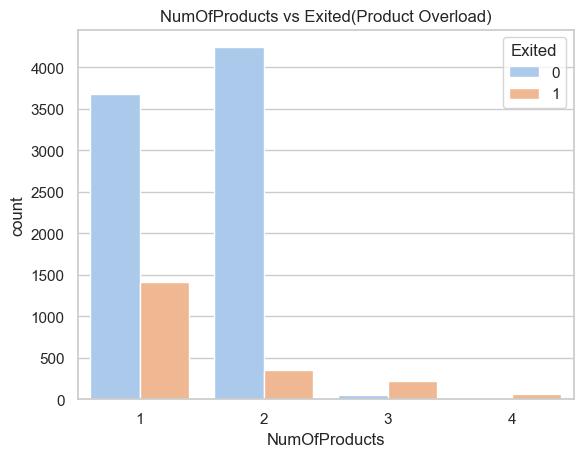

In [8]:
plot4 = sns.countplot(data=df, x='NumOfProducts', hue='Exited')
plot4.set_title("NumOfProducts vs Exited(Product Overload)")

Text(0.5, 1.0, 'Financial Health(balance vs exited)')

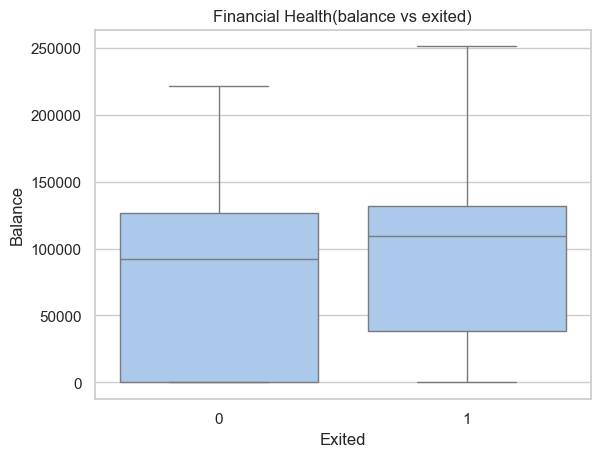

In [9]:
plot5 = sns.boxplot(data=df, x='Exited', y='Balance')
plot5.set_title("Financial Health(balance vs exited)")
# fig = plot5.get_figure()
# fig.savefig("./images/financialhealth_vs_exited.png", dpi=300, bbox_inches='tight')

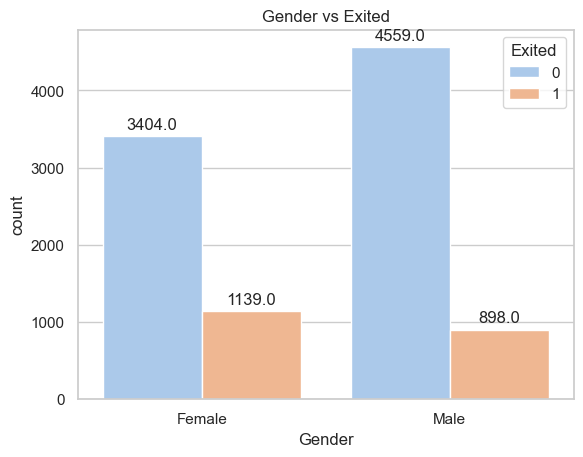

In [10]:
plot6 = sns.countplot(data=df, x='Gender', hue='Exited')
plot6.set_title("Gender vs Exited")
for container in plot6.containers:
    labels = [f'{v.get_height()}' for v in container]
    plot6.bar_label(container, labels=labels, padding=3)
    
# fig = plot6.get_figure()
# fig.savefig("./images/gender_vs_exited.png", dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Tenure vs Exited')

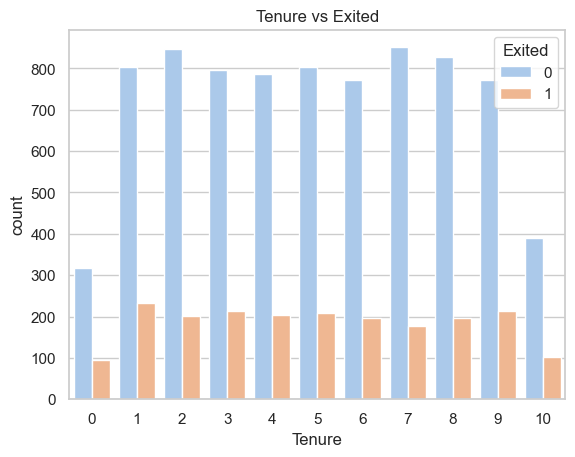

In [11]:
plot7 = sns.countplot(data=df, x='Tenure', hue='Exited')
plot7.set_title("Tenure vs Exited")

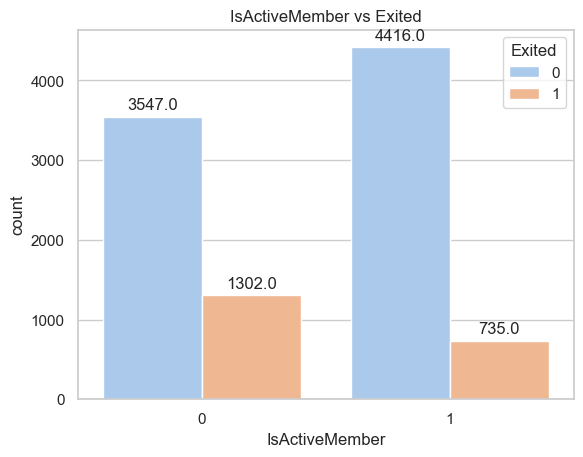

In [12]:
plot8 = sns.countplot(data=df, x='IsActiveMember', hue='Exited')
plot8.set_title("IsActiveMember vs Exited")
for container in plot8.containers:
    labels = [f'{v.get_height()}' for v in container]
    plot8.bar_label(container, labels=labels, padding=3)

In [13]:
# print(df.info())
# unique_geography_rows = df["Geography"].unique().tolist()
# print(unique_geography_rows)
df = pd.get_dummies(data = df, columns = ["Geography"], drop_first = True)
df["Gender"] = df["Gender"].map({'Female': 0, 'Male': 1})
# print(df.info())

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  int64  
 1   Gender             10000 non-null  int64  
 2   Age                10000 non-null  int64  
 3   Tenure             10000 non-null  int64  
 4   Balance            10000 non-null  float64
 5   NumOfProducts      10000 non-null  int64  
 6   HasCrCard          10000 non-null  int64  
 7   IsActiveMember     10000 non-null  int64  
 8   EstimatedSalary    10000 non-null  float64
 9   Exited             10000 non-null  int64  
 10  Geography_Germany  10000 non-null  bool   
 11  Geography_Spain    10000 non-null  bool   
dtypes: bool(2), float64(2), int64(8)
memory usage: 800.9 KB


In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

cols_to_scale = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  float64
 1   Gender             10000 non-null  int64  
 2   Age                10000 non-null  float64
 3   Tenure             10000 non-null  float64
 4   Balance            10000 non-null  float64
 5   NumOfProducts      10000 non-null  float64
 6   HasCrCard          10000 non-null  int64  
 7   IsActiveMember     10000 non-null  int64  
 8   EstimatedSalary    10000 non-null  float64
 9   Exited             10000 non-null  int64  
 10  Geography_Germany  10000 non-null  bool   
 11  Geography_Spain    10000 non-null  bool   
dtypes: bool(2), float64(6), int64(4)
memory usage: 800.9 KB
